**How much annotated data does cybersecurity entity recognition need?**

This notebook fine tunes bert-base-uncased on CyNER and APTNER with different amounts of training data. It measures how span level F1 scales with the number of annotated sentences.

Includeds two learning curve sweeps. Together it takes about 90 minutes on T4.

**Setup**

Installs seqeval and the spaCy model. Seqeval is installed with a pinned setuptools_scm because the default install failed on Colab.

Results are downloaded.

In [ ]:
# Used pips documentation for how to install: https://pip.pypa.io/en/stable/cli/pip_install/
!pip install -q "setuptools_scm<8"
!pip install -q --no-build-isolation seqeval
!python -m spacy download en_core_web_sm

# Everything is written to the sessions disk and then downloaded manually after.
OUT = "/content"

  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


**Data and datasets**

Downloads CyNER MITRE and reads it into sentences. It skips malformed lines and reports how many there are. What is printed here are the ones in the CyNER section of the Methodology. The entity counts match those published by Alam et al. The sentence and token counts are counted from the files.

In [ ]:
# CyNER MITRE split. source for the CyNER: https://github.com/aiforsec/CyNER
from collections import Counter

CYNER = "https://raw.githubusercontent.com/aiforsec/CyNER/main/dataset/mitre"
for split in ["train", "valid", "test"]:
    !wget -q -O {split}.txt {CYNER}/{split}.txt

# Table setup
def read_conll(path):
    sents, toks, tags, bad = [], [], [], 0
    for line in open(path, encoding="utf-8"):
        if not line.strip():
            if toks:
                sents.append((toks, tags))
                toks, tags = [], []
            continue
        parts = line.split()
        if len(parts) != 2:
            bad += 1
            continue
        toks.append(parts[0])
        tags.append(parts[1])
    if toks:
        sents.append((toks, tags))
    if bad:
        print(f"{path}: skipped {bad} malformed lines")
    return sents

for split in ["train", "valid", "test"]:
    sents = read_conll(f"{split}.txt")
    counts = Counter(t[2:] for _, tags in sents for t in tags if t.startswith("B-"))
    print(f"\n{split}: {len(sents)} sentences, {sum(len(t) for t, _ in sents)} tokens")
    for name in sorted(counts):
        print(f"  {name:<15}{counts[name]}")
    print(f"  {'total':<15}{sum(counts.values())}")


train: 2811 sentences, 68191 tokens
  Indicator      1021
  Malware        703
  Organization   284
  System         837
  Vulnerability  48
  total          2893

valid: 813 sentences, 19530 tokens
  Indicator      208
  Malware        254
  Organization   92
  System         182
  Vulnerability  9
  total          745

test: 748 sentences, 19270 tokens
  Indicator      261
  Malware        242
  Organization   131
  System         248
  Vulnerability  10
  total          892


**Labels and subwords**

Builds 11 label BIO scheme and lines up word level tags onto BERT's subword tokens. Each word label goes on first subword. Continuation subwords and the special tokens are set to -100 and are ignored by the loss.
The check at the end counts sentences where the number of labelled positions does not equal the number of surviving words. A fault here would leave training working and the reported F1 meaningless. The cut off point count is reported in the paper.

In [ ]:

# Subword alignment follows HuggingFace's token classification guide.
# src: https://huggingface.co/docs/transformers/tasks/token_classification
from transformers import AutoTokenizer

MODEL = "bert-base-uncased"
MAX_LEN = 128                 # CyNER's settings. src: https://arxiv.org/abs/2204.05754
CY_types = ["Indicator", "Malware", "Organisation", "System", "Vulnerability"]

cy_labels = ["O"] + [f"{p}-{t}" for t in CY_types for p in ("B", "I")]
cy_lab2id = {l: i for i, l in enumerate(cy_labels)}
cy_id2lab = {i: l for l, i in cy_lab2id.items()}

tok = AutoTokenizer.from_pretrained(MODEL)

def cy_encode(toks, tags):
    enc = tok(toks, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    out, prev = [], None
    for wid in enc.word_ids():
        # -100 is CrossEntropyLoss's default ignore_index, so special tokens and continuation subwords contribute nothing loss.
        # src: https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
        out.append(-100 if wid is None or wid == prev else cy_lab2id[tags[wid]])
        prev = wid
    enc["labels"] = out
    return enc

train_sents = read_conll("train.txt")
misaligned = cut = 0
for toks, tags in train_sents:
    enc = cy_encode(toks, tags)
    words = {w for w in enc.word_ids() if w is not None}
    if sum(1 for l in enc["labels"] if l != -100) != len(words):
        misaligned += 1
    if len(words) < len(toks):
        cut += 1
print("misaligned:", misaligned, " Cut off:", cut, "of", len(train_sents))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

misaligned: 0  truncated: 47 of 2811


**Evaluation**

Converts the three splits into HuggingFace datasets and defines the decoding used for evaluation. All scores are span level and computed. This follows CoNLL-2003 protocol. A predicted entity counts as correct if both boundaries and the type match the annotation.

In [ ]:
# Span level scoring, CoNLL-2003 protocol. src: https://github.com/chakki-works/seqeval
import numpy as np
from datasets import Dataset
from seqeval.metrics import classification_report, f1_score

def build(path):
    return Dataset.from_list([dict(cy_encode(t, g)) for t, g in read_conll(path)])

train_ds, dev_ds, test_ds = build("train.txt"), build("valid.txt"), build("test.txt")

def cy_decode(logits, label_ids):
    preds = np.argmax(logits, axis=2)
    pred = [[cy_id2lab[a] for a, b in zip(p, g) if b != -100] for p, g in zip(preds, label_ids)]
    true = [[cy_id2lab[b] for a, b in zip(p, g) if b != -100] for p, g in zip(preds, label_ids)]
    return pred, true

**Validation**

I trains once on the full training set and evaluates on the test split. The result is compared against the 69.77 micro F1 that Alam et al. report for bert-base-uncased on the same data. This is run before the sweep so that a fault in the pipeline is caught before the training.

Hyperparameters are taken from CyNER: 20 epochs, learning rate 1e-5, batch size 32, maximum sequence length 128. Training runs for a fixed number of epochs.

The micro F1 printed here is the result in the Pipeline Validation section of the Results.

In [ ]:
# Hyperparameters taken from CyNER section 5.1 so the result is comparable with
# their 69.77 micro F1. src: https://arxiv.org/abs/2204.05754
import json
from transformers import (AutoModelForTokenClassification,
                          DataCollatorForTokenClassification,
                          TrainingArguments, Trainer)

EPOCHS, LR, BATCH = 20, 1e-5, 32

def make_trainer(ds, seed, outdir, labels, lab2id, id2lab, eval_ds=None):
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL, num_labels=len(labels), id2label=id2lab, label2id=lab2id)
    args = TrainingArguments(
        output_dir=outdir, num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        learning_rate=LR, seed=seed, fp16=True, report_to=[],
        eval_strategy="epoch" if eval_ds else "no",
        save_strategy="no", logging_strategy="no")
    return Trainer(model=model, args=args, train_dataset=ds, eval_dataset=eval_ds,
                   data_collator=DataCollatorForTokenClassification(tok),
                   processing_class=tok)

try:
    # Reuse run so confusion matrix in report stays the same.
    d = json.load(open(f"{OUT}/cyner_test_predictions.json"))
    pred, true = d["pred"], d["true"]
except FileNotFoundError:
    trainer = make_trainer(train_ds, 42, "out/validate",
                           cy_labels, cy_lab2id, cy_id2lab, eval_ds=dev_ds)
    trainer.train()
    out = trainer.predict(test_ds)
    pred, true = cy_decode(out.predictions, out.label_ids)
    json.dump({"pred": pred, "true": true,
               "sents": [t for t, _ in read_conll("test.txt")]},
              open(f"{OUT}/cyner_test_predictions.json", "w"))

print(classification_report(true, pred, digits=4))
print("micro F1:", f1_score(true, pred))

               precision    recall  f1-score   support

    Indicator     0.6667    0.8027    0.7284       294
      Malware     0.7205    0.7593    0.7394       241
 Organization     0.5364    0.4403    0.4836       134
       System     0.5187    0.5605    0.5388       248
Vulnerability     0.7500    0.6000    0.6667        10

    micro avg     0.6268    0.6721    0.6486       927
    macro avg     0.6384    0.6326    0.6314       927
 weighted avg     0.6231    0.6721    0.6445       927

micro F1: 0.648620510150963


**Environment**

Counts orphan I- tags in test split and test sentences lost to
cut off. They explain why seqeval counts a different number of annotated entities than count of B- tags.

In [ ]:
# Both counts explain why seqeval reports a different number of trueentities
# than a count of B- tags. src: https://github.com/chakki-works/seqeval
import sys, torch, transformers, datasets
from importlib.metadata import version

test_sents = read_conll("test.txt")
orphans = sum(1 for _, tags in test_sents for prev, t in zip(["O"] + tags, tags)
              if t.startswith("I-") and prev not in (f"B-{t[2:]}", f"I-{t[2:]}"))
cut = sum(1 for t, g in test_sents
          if len({w for w in cy_encode(t, g).word_ids() if w is not None}) < len(t))
print("orphan I- tags in test:", orphans)
print("truncated test sentences:", cut)

!nvidia-smi --query-gpu=name --format=csv,noheader
print(sys.version.split()[0], torch.__version__, transformers.__version__,
      datasets.__version__, version("seqeval"))

orphan I- tags in test: 44
truncated test sentences: 11
Tesla T4
3.13.16 2.11.0+cu130 5.22.0 4.8.5 1.2.2


**CyNER learning curve**

Trains on random subsets of the training split at eight sizes, three times each with different seeds, and evaluates every model on the same full test split.

Sentences are sampled and not divided by entity type.

The results feeds the CyNER learning curve and per type results in the Results section.

In [ ]:
# Mean and spread over repeated runs.
# src: https://aclanthology.org/D19-1224/
import json, os, random

CY_SIZES = [50, 100, 200, 250, 500, 1000, 2000, 2811]
SEEDS = [67, 68, 69]
CY_FILE = f"{OUT}/cyner_results.json"

def types_in(sents):
    return dict(Counter(t[2:] for _, tags in sents for t in tags if t.startswith("B-")))

def run_cy(n, seed):
    # random.Random(seed) gives each (n, seed) pair same draw.
    # src: https://docs.python.org/3/library/random.html
    sample = random.Random(seed).sample(train_sents, n)
    ds = Dataset.from_list([dict(cy_encode(t, g)) for t, g in sample])
    trainer = make_trainer(ds, seed, f"out/{n}_{seed}", cy_labels, cy_lab2id, cy_id2lab)
    trainer.train()
    out = trainer.predict(test_ds)
    pred, true = cy_decode(out.predictions, out.label_ids)
    # zero_division=0 because small subsets leave some types with no predictions at all.
    # src: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
    rep = classification_report(true, pred, output_dict=True, zero_division=0)
    return {"n": n, "seed": seed, "support": types_in(sample),
            "micro_f1": f1_score(true, pred),
            "per_class": {k: v for k, v in rep.items() if not k.endswith("avg")}}

cy_res = []
if os.path.exists(CY_FILE):
    try:
        cy_res = json.load(open(CY_FILE))
    except json.JSONDecodeError:
        cy_res = []          # run killed mid write leaves empty file
done = {(r["n"], r["seed"]) for r in cy_res}

for n in CY_SIZES:
    for seed in SEEDS:
        if (n, seed) in done:
            continue
        cy_res.append(run_cy(n, seed))
        # Written after every run (Colab disconnects)
        json.dump(cy_res, open(CY_FILE, "w"), default=float)
        print(f"n={n:5d} seed={seed}  {cy_res[-1]['micro_f1']:.4f}")

# Had to download when a sweep finishes
# src: https://colab.research.google.com/notebooks/io.ipynb
from google.colab import files
files.download(CY_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Baseline**

Runs spaCy's en_core_web_sm over test split with no training on CyNER. Model is given the datasets existing tokenisation, so no character offset alignment needed.

Two measures are reported. Organisation is compared directly against spaCy's ORG label. This is the only pair that refers to the same thing. For the other four types spaCy has no corresponding label.

The output is the table in the Baseline section of the Results.

In [ ]:
# Doc(vocab, words=...) makes spaCy accept the dataset's tokenisation instead of running its own
# Avoids character offset alignment.
# src: https://spacy.io/api/doc
import spacy
from spacy.tokens import Doc
from collections import defaultdict
from seqeval.metrics.sequence_labeling import get_entities

nlp = spacy.load("en_core_web_sm")

true_spans, pred_spans = [], []
for i, (toks, tags) in enumerate(test_sents):
    # get_entities is seqeval's own span extractor, so these spans are the same ones behind every other number in the paper.
    # src: https://github.com/chakki-works/seqeval
    true_spans += [(i, t, s, e) for t, s, e in get_entities(tags)]
    doc = nlp(Doc(nlp.vocab, words=toks))
    pred_spans += [(i, ent.label_, ent.start, ent.end - 1) for ent in doc.ents]

true_org = {(i, s, e) for i, t, s, e in true_spans if t == "Organisation"}
pred_org = {(i, s, e) for i, t, s, e in pred_spans if t == "ORG"}
hit = len(true_org & pred_org)
p, r = hit / len(pred_org), hit / len(true_org)
print(f"Organisation  P {p:.3f}  R {r:.3f}  F1 {2*p*r/(p+r):.3f}")
print(f"spaCy predicted {len(pred_spans)} spans against {len(true_spans)} true entities")

by_sent = defaultdict(list)
for i, t, s, e in pred_spans:
    by_sent[i].append((t, s, e))

for ent_type in CY_types:
    true_spans_of_type = [(i, s, e) for i, t, s, e in true_spans if t == ent_type]
    found, seen = 0, Counter()
    for i, s, e in true_spans_of_type:
        # The question is if anything is detected at all, since spaCy has no label for four of the five types.
        over = [t for t, ps, pe in by_sent[i] if ps <= e and pe >= s]
        if over:
            found += 1
            seen.update(over)
    print(f"{ent_type:<15}{len(true_spans_of_type):>5}{found:>7}{found/len(true_spans_of_type):>8.1%}   "
          + ", ".join(f"{l} {c}" for l, c in seen.most_common(3)))

Organization  P 0.127  R 0.530  F1 0.204
spaCy predicted 1205 spans against 936 true entities
Indicator        301     60   19.9%   CARDINAL 18, ORG 16, PRODUCT 12
Malware          242    187   77.3%   ORG 147, PERSON 26, DATE 9
Organization     134    117   87.3%   ORG 98, PERSON 13, GPE 6
System           249    187   75.1%   ORG 110, PERSON 33, PRODUCT 17
Vulnerability     10      4   40.0%   ORG 2, GPE 2


**APTNER**

Downloads APTNER, the second corpus. Annotates threat intelligence reports with 21 entity types against CyNER's five.

Two things differ. The tagging scheme is BIOES. This is converted to BIO at read time so that both corpora go through one evaluation path. The tag inventory contains annotation errors, a bare PROT tag with no prefix and two doubled prefixes. Sentences containing these are dropped whole, as well as sentences containing a line that does not split into two fields. Dropping the line instead would leave a sentence missing a token in the middle.

The dropped counts are reported in the Methodology.

The label list is built from the union of all three splits. A type appearing only in dev or test would raise an error partway through an unattended sweep.

In [ ]:
# Second corpus, 21 entity types. src: https://github.com/wangxuren/APTNER
APTNER = "https://raw.githubusercontent.com/wangxuren/APTNER/main"
for split in ["train", "dev", "test"]:
    !wget -q -O apt_{split}.txt {APTNER}/APTNER{split}.txt

PREFIXES = {"B", "I", "E", "S"}

def to_bio(tag):
    # APTNER uses BIOES. S- is a one token entity, so B-, and E- is the last token inside one, so I-.
    #Span boundaries are unchanged. Keeps one evaluation path for both corpora.
    # The two schemes are compared in Ratinov and Roth (2009).
    # src: https://aclanthology.org/W09-1119/
    if tag == "O":
        return "O"
    prefix, sep, etype = tag.partition("-")
    if not sep or prefix not in PREFIXES or etype.partition("-")[0] in PREFIXES:
        return None
        # 'PROT' and 'E-S-SECTEAM' are annotation errors
    return f"B-{etype}" if prefix == "S" else f"I-{etype}" if prefix == "E" else tag

def read_aptner(path):
    sents, toks, tags, bad, dropped = [], [], [], False, 0
    for line in open(path, encoding="utf-8"):
        if not line.strip():
            if bad:
                dropped += 1
            elif toks:
                sents.append((toks, tags))
            toks, tags, bad = [], [], False
            continue
        parts = line.split()
        tag = to_bio(parts[1]) if len(parts) == 2 else None
        if tag is None:
            # Drops sentence, not line.
            bad = True
            continue
        toks.append(parts[0])
        tags.append(tag)
    if toks and not bad:
        sents.append((toks, tags))
    print(f"{path}: kept {len(sents)}, dropped {dropped}")
    return sents

apt = {s: read_aptner(f"apt_{s}.txt") for s in ["train", "dev", "test"]}
for split, sents in apt.items():
    counts = Counter(t.split("-", 1)[1] for _, tags in sents
                     for t in tags if t.startswith("B-"))
    print(f"\n{split}: {len(sents)} sentences, {sum(len(t) for t, _ in sents)} tokens, "
          f"{sum(counts.values())} entities")
    for name, c in sorted(counts.items(), key=lambda kv: -kv[1]):
        print(f"  {name:<12}{c}")

# Union of all splits. A type seen only in dev or test cannot raise a KeyError partway.
APT_TYPES = sorted({t.split("-", 1)[1] for s in apt.values()
                    for _, tags in s for t in tags if t != "O"})
apt_labels = ["O"] + [f"{p}-{t}" for t in APT_TYPES for p in ("B", "I")]
print(len(apt_labels), "labels")

apt_train.txt: kept 6503, dropped 242
apt_dev.txt: kept 1727, dropped 25
apt_test.txt: kept 1531, dropped 14

train: 6503 sentences, 176731 tokens, 21239 entities
  APT         3606
  MAL         3031
  IDTY        2868
  LOC         2552
  TOOL        1708
  ACT         1632
  TIME        1514
  FILE        1308
  SECTEAM     1049
  VULNAME     482
  VULID       413
  DOM         234
  OS          189
  SHA2        156
  PROT        140
  IP          115
  ENCR        92
  MD5         67
  URL         60
  SHA1        12
  EMAIL       11

dev: 1727 sentences, 38227 tokens, 3312 entities
  TOOL        802
  MAL         367
  APT         344
  IDTY        334
  TIME        250
  LOC         236
  FILE        235
  DOM         87
  PROT        87
  SECTEAM     85
  ACT         82
  OS          80
  SHA2        66
  MD5         66
  ENCR        60
  IP          59
  VULID       24
  URL         23
  VULNAME     16
  SHA1        9

test: 1531 sentences, 38540 tokens, 3337 entities
  TOOL  

**APTNER learning curve**

Repeats the sweep on APTNER with the same protocol.

The sizes repeats CyNER's sizes up to 2000 so the curves can be compared at those budgets, then adds 4000 and the full training set.

In [ ]:
# Same protocol as the CyNER sweep so the two curves are comparable.
apt_lab2id = {l: i for i, l in enumerate(apt_labels)}
apt_id2lab = {i: l for l, i in apt_lab2id.items()}

def apt_encode(toks, tags):
    # Same alignment rule as cy_encode.
    # src: https://huggingface.co/docs/transformers/tasks/token_classification
    enc = tok(toks, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    out, prev = [], None
    for wid in enc.word_ids():
        out.append(-100 if wid is None or wid == prev else apt_lab2id[tags[wid]])
        prev = wid
    enc["labels"] = out
    return enc

def apt_decode(logits, label_ids):
    preds = np.argmax(logits, axis=2)
    pred = [[apt_id2lab[a] for a, b in zip(p, g) if b != -100] for p, g in zip(preds, label_ids)]
    true = [[apt_id2lab[b] for a, b in zip(p, g) if b != -100] for p, g in zip(preds, label_ids)]
    return pred, true

apt_train = apt["train"]
apt_test_ds = Dataset.from_list([dict(apt_encode(t, g)) for t, g in apt["test"]])

APT_SIZES = [50, 100, 200, 250, 500, 1000, 2000, 4000, len(apt_train)]
APT_FILE = f"{OUT}/aptner_results.json"

def run_apt(n, seed):
    sample = random.Random(seed).sample(apt_train, n)
    ds = Dataset.from_list([dict(apt_encode(t, g)) for t, g in sample])
    trainer = make_trainer(ds, seed, f"out_apt/{n}_{seed}",
                           apt_labels, apt_lab2id, apt_id2lab)
    trainer.train()
    out = trainer.predict(apt_test_ds)
    pred, true = apt_decode(out.predictions, out.label_ids)
    rep = classification_report(true, pred, output_dict=True, zero_division=0)
    return {"n": n, "seed": seed,
            "support": dict(Counter(t.split("-", 1)[1] for _, tags in sample
                                    for t in tags if t.startswith("B-"))),
            "micro_f1": f1_score(true, pred),
            "per_class": {k: v for k, v in rep.items() if not k.endswith("avg")}}

apt_res = []
if os.path.exists(APT_FILE):
    try:
        apt_res = json.load(open(APT_FILE))
    except json.JSONDecodeError:
        apt_res = []
apt_done = {(r["n"], r["seed"]) for r in apt_res}

for n in APT_SIZES:
    for seed in SEEDS:
        if (n, seed) in apt_done:
            continue
        apt_res.append(run_apt(n, seed))
        json.dump(apt_res, open(APT_FILE, "w"), default=float)
        print(f"n={n:5d} seed={seed}  {apt_res[-1]['micro_f1']:.4f}")

from google.colab import files
files.download(APT_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Figures and tables**

Produces three figures and prints the numbers in the Results. Figure 3 normalises each dataset by its own full data score. Absolute F1 is not comparable across the two corpora, because the schemas, the corpus sizes. The fraction of each dataset's own achievable performance that a given budget buys is comparable. That is what the research question asks about.

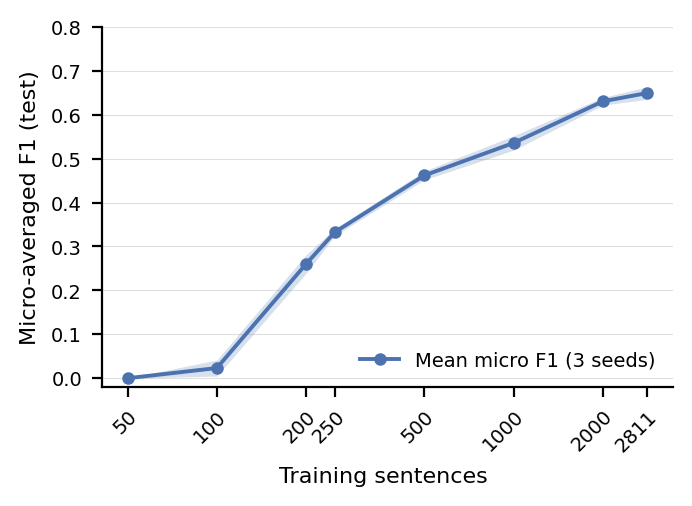

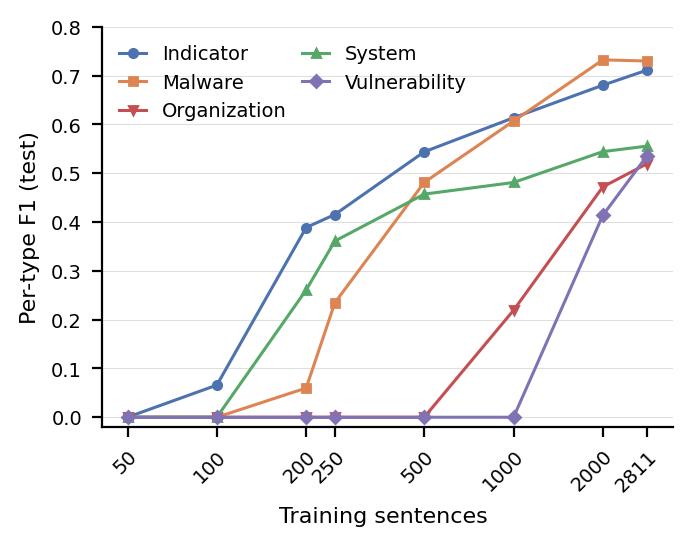

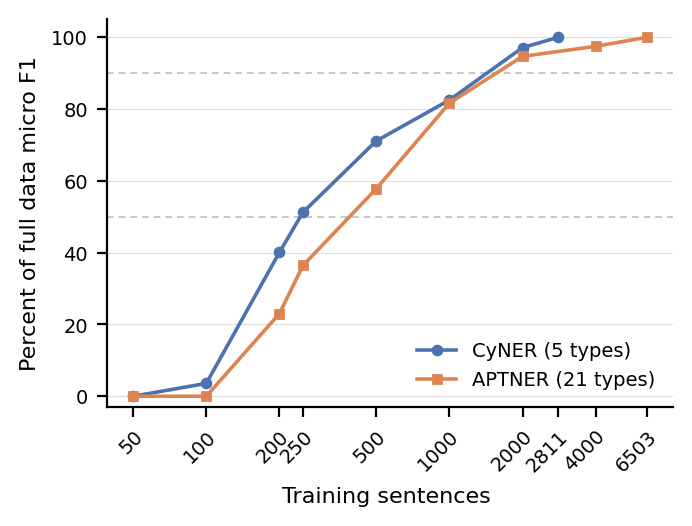


CyNER: full data 0.6491
     50  0.0000    0.0%
    100  0.0232    3.6%
    200  0.2603   40.1%
    250  0.3326   51.2%
    500  0.4616   71.1%
   1000  0.5356   82.5%
   2000  0.6304   97.1%
   2811  0.6491  100.0%
  50% reached at n = 250
  90% reached at n = 2000
  95% reached at n = 2000

APTNER: full data 0.5983
     50  0.0000    0.0%
    100  0.0000    0.0%
    200  0.1378   23.0%
    250  0.2180   36.4%
    500  0.3457   57.8%
   1000  0.4885   81.6%
   2000  0.5665   94.7%
   4000  0.5832   97.5%
   6503  0.5983  100.0%
  50% reached at n = 500
  90% reached at n = 2000
  95% reached at n = 4000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Learning curve plotted as mean with standard deviation band.
# Inspired by scikit-learn's learning_curve.
# src: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html
import matplotlib.pyplot as plt

COL_WIDTH = 3.33

plt.rcParams.update({"font.size": 8, "axes.labelsize": 8, "legend.fontsize": 7,
                     "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 200})

def load_runs(path):
    by = defaultdict(list)
    for r in json.load(open(path)):
        by[r["n"]].append(r)
    return by

def mean_sd(by, sizes):
    m = np.array([np.mean([r["micro_f1"] for r in by[n]]) for n in sizes])
    s = np.array([np.std([r["micro_f1"] for r in by[n]]) for n in sizes])
    return m, s

def log_axis(ax, sizes):
    # Log scale because sizes are geometric and sharpest change falls between 100 and 250.
    # src: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html
    ax.set_xscale("log")
    ax.set_xticks(sizes)
    ax.set_xticklabels([str(n) for n in sizes], rotation=45, ha="right",
                       rotation_mode="anchor")
    ax.minorticks_off()
    ax.set_xlabel("Training sentences ")
    ax.grid(axis="y", linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)

cy_by = load_runs(CY_FILE)
cy_sizes = sorted(cy_by)
cy_mean, cy_sd = mean_sd(cy_by, cy_sizes)

fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.4))
ax.fill_between(cy_sizes, cy_mean - cy_sd, cy_mean + cy_sd,
                color="#4C72B0", alpha=0.22, lw=0)
ax.plot(cy_sizes, cy_mean, "o-", ms=3.5, lw=1.4, color="#4C72B0",
        label="Mean micro F1 (3 seeds)")
log_axis(ax, cy_sizes)
ax.set_ylabel("Micro-averaged F1 (test)")
ax.set_ylim(-0.02, 0.8)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(pad=0.3)
fig.savefig(f"{OUT}/fig1.pdf")
plt.show()

# Design of the model
STYLE = {"Indicator": ("#4C72B0", "o"), "Malware": ("#DD8452", "s"),
         "System": ("#55A868", "^"), "Organisation": ("#C44E52", "v"),
         "Vulnerability": ("#8172B3", "D")}

fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.6))
for t in CY_types:
    colour, marker = STYLE[t]
    y = [np.mean([r["per_class"][t]["f1-score"] for r in cy_by[n]]) for n in cy_sizes]
    ax.plot(cy_sizes, y, marker=marker, ms=3, lw=1.1, color=colour, label=t)
log_axis(ax, cy_sizes)
ax.set_ylabel("Per-type F1 (test)")
ax.set_ylim(-0.02, 0.8)
ax.legend(loc="upper left", frameon=False, ncol=2, columnspacing=0.8, handlelength=1.4)
fig.tight_layout(pad=0.3)
fig.savefig(f"{OUT}/fig2.pdf")
plt.show()

apt_by = load_runs(APT_FILE)
apt_sizes = sorted(apt_by)
apt_mean, _ = mean_sd(apt_by, apt_sizes)

# Corpuses is normalised by own full data score.
fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.5))
for y in (50, 90):
    ax.axhline(y, color="0.75", lw=0.6, ls=(0, (4, 3)), zorder=0)
ax.plot(cy_sizes, 100 * cy_mean / cy_mean[-1], "o-", ms=3.2, lw=1.3,
        color="#4C72B0", label="CyNER (5 types)")
ax.plot(apt_sizes, 100 * apt_mean / apt_mean[-1], "s-", ms=3.2, lw=1.3,
        color="#DD8452", label="APTNER (21 types)")
log_axis(ax, sorted(set(cy_sizes) | set(apt_sizes)))
ax.set_ylabel("Percent of full data micro F1")
ax.set_ylim(-3, 105)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(pad=0.3)
fig.savefig(f"{OUT}/fig3.pdf")
plt.show()

for name, sizes, m in [("CyNER", cy_sizes, cy_mean), ("APTNER", apt_sizes, apt_mean)]:
    print(f"\n{name}: full data {m[-1]:.4f}")
    for n, v in zip(sizes, m):
        print(f"  {n:5d}  {v:.4f}  {100*v/m[-1]:5.1f}%")
    for frac in (0.5, 0.9, 0.95):
        print(f"  {frac:.0%} reached at n =",
              next((s for s, v in zip(sizes, m) if v >= frac * m[-1]), None))


from google.colab import files
for f in ["fig1.pdf", "fig2.pdf", "fig3.pdf"]:
    files.download(f"{OUT}/{f}")

**APTNER predictions for error analysis**

Sweep discards each model after scoring it, so no predictions survive. This cell trains once more on the full APTNER training set and saves the predicted and true tag sequences together with the test sentences. The error analysis then runs on CPU without retraining anything.

One seed is used, because error analysis reads individual mistakes. The per type scores printed here are not the ones reported in the paper, which come from the three seed sweep.

In [ ]:
# One full data run kept only for the error analysis.
trainer = make_trainer(
    Dataset.from_list([dict(apt_encode(t, g)) for t, g in apt_train]),
    67, "out_apt/errors", apt_labels, apt_lab2id, apt_id2lab)
trainer.train()
out = trainer.predict(apt_test_ds)
pred, true = apt_decode(out.predictions, out.label_ids)
json.dump({"pred": pred, "true": true, "sents": [t for t, _ in apt["test"]]},
          open(f"{OUT}/aptner_test_predictions.json", "w"))
print(classification_report(true, pred, digits=4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

Step,Training Loss


/usr/local/lib/python3.13/dist-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

         ACT     0.1096    0.6154    0.1860        52
         APT     0.6918    0.6977    0.6947       473
         DOM     0.5000    0.7436    0.5979        39
       EMAIL     0.0000    0.0000    0.0000        22
        ENCR     1.0000    0.6667    0.8000        24
        FILE     0.4481    0.7263    0.5542        95
        IDTY     0.1371    0.3280    0.1934       125
          IP     0.9697    0.9412    0.9552        34
         LOC     0.6364    0.8485    0.7273       165
         MAL     0.5559    0.7010    0.6201       709
         MD5     0.0000    0.0000    0.0000        12
          OS     0.8387    0.7429    0.7879        35
        PROT     0.7018    0.4706    0.5634        85
     SECTEAM     0.8469    0.8830    0.8646       188
        SHA2     0.6667    1.0000    0.8000        26
        TIME     0.6507    0.7011    0.6750       271
        TOOL     0.7388    0.4356    0.5481       870
         URL     0.4706    

**Analysis of learning curve**

Three measures computed from the saved sweep results. No model is trained here.

First, number of annotated instances of each type present when that type stops scoring zero.

Second, micro against macro averaged F1 at every size. Micro weights each entity equally and macro weights each type equally, so the gap between them measures how much of the reported score comes from the frequent types.

Third is weighted precision and recall at every size. Shows if additional annotation buys detection or correctness.

In [ ]:
# Analysis numbers. All computed from the saved sweep results.
import statistics as st

cy_by = load_runs(CY_FILE)
cy_sizes = sorted(cy_by)

# Instance thresholds. Sentences are the budget a practitioner spends, but instances are what the model learns from, and the two differ by type.
print("type           last zero          first non-zero")
for t in CY_types:
    prev = None
    for n in cy_sizes:
        inst = sum(r["support"].get(t, 0) for r in cy_by[n]) / 3
        f = [r["per_class"][t]["f1-score"] for r in cy_by[n]]
        if any(x > 0 for x in f):
            print(f"{t:14s} {prev[0]:6.1f} (n={prev[1]:4d})   "
                  f"{inst:6.1f} (n={n:4d})  F1 {sum(f)/3:.3f}")
            break
        prev = (inst, n)

# Micro against macro. Micro weights by entity count, macro by type. The gap measures how much of the score sits in the frequent types.
# src: https://scikit-learn.org/stable/modules/model_evaluation.html
print("\nsize   micro   macro    gap     wP      wR")
W = {t: cy_by[cy_sizes[-1]][0]["per_class"][t]["support"] for t in CY_types}
tot = sum(W.values())
for n in cy_sizes:
    micro = sum(r["micro_f1"] for r in cy_by[n]) / 3
    macro = sum(sum(r["per_class"][t]["f1-score"] for r in cy_by[n]) / 3
                for t in CY_types) / len(CY_types)
    wP = sum(W[t] * sum(r["per_class"][t]["precision"] for r in cy_by[n]) / 3
             for t in CY_types) / tot
    wR = sum(W[t] * sum(r["per_class"][t]["recall"] for r in cy_by[n]) / 3
             for t in CY_types) / tot
    print(f"{n:5d}  {micro:.4f}  {macro:.4f}  {micro-macro:.4f}  {wP:.3f}  {wR:.3f}")

# Per type scores at full training size, averaged over three seeds.
# These are the numbers in the Per Type Results section of report.
print("\ntype            P      R      F1     sd     test sup")
for t in CY_types:
    rs = cy_by[cy_sizes[-1]]
    f = [r["per_class"][t]["f1-score"] for r in rs]
    print(f"{t:14s} {sum(r['per_class'][t]['precision'] for r in rs)/3:.3f}  "
          f"{sum(r['per_class'][t]['recall'] for r in rs)/3:.3f}  "
          f"{sum(f)/3:.3f}  {st.pstdev(f):.3f}  {rs[0]['per_class'][t]['support']:6.0f}")

type           last zero          first non-zero
Indicator        15.3 (n=  50)     46.3 (n= 100)  F1 0.066
Malware          22.7 (n= 100)     46.3 (n= 200)  F1 0.060
Organization     47.7 (n= 500)    103.3 (n=1000)  F1 0.219
System           22.0 (n= 100)     49.3 (n= 200)  F1 0.261
Vulnerability    18.3 (n=1000)     34.7 (n=2000)  F1 0.414

size   micro   macro    gap     wP      wR
   50  0.0000  0.0000  0.0000  0.000  0.000
  100  0.0232  0.0132  0.0100  0.073  0.012
  200  0.2603  0.1419  0.1184  0.334  0.205
  250  0.3326  0.2023  0.1304  0.306  0.312
  500  0.4616  0.2965  0.1651  0.371  0.487
 1000  0.5356  0.3841  0.1514  0.490  0.568
 2000  0.6304  0.5686  0.0618  0.608  0.654
 2811  0.6491  0.6101  0.0390  0.629  0.668

type            P      R      F1     sd     test sup
Indicator      0.655  0.778  0.711  0.015     294
Malware        0.703  0.759  0.730  0.022     241
Organization   0.596  0.460  0.519  0.020     134
System         0.545  0.567  0.555  0.015     248
Vulner

**Error analysis**

Span level confusion built from saved predictions. For each true entity the cell asks if a predicted entity with same boundaries exists and what type it carried. Entities predicted where no true entity exists are counted separately as unmatched. Boundaries must match exactly. This is the same criterion used for every other score in report.

The second half prints fifteen individual errors with their surrounding context. These are read by hand and the ones discussed in the Analysis section are drawn from them.

In [ ]:
# Span level confusion. For each true span, did a predicted span with the same boundaries exist, and what type did it carry.
from seqeval.metrics.sequence_labeling import get_entities

d = json.load(open(f"{OUT}/cyner_test_predictions.json"))
conf = Counter()
for pred_seq,true_seq in zip(d["pred"], d["true"]):
    g = {(s, e): t for t, s, e in get_entities(true_seq)}
    p = {(s, e): t for t, s, e in get_entities(pred_seq)}
    for span, t in g.items():
        conf[(t, p.get(span, "MISSED"))] += 1
    for span, t in p.items():
        if span not in g:
            conf[("UNMATCHED", t)] += 1

types = CY_types + ["MISSED"]
print("true \\ pred   " + "".join(f"{t[:6]:>8}" for t in types))
for g in CY_types:
    print(f"{g:14s}" + "".join(f"{conf[(g, p)]:8d}" for p in types))
print("UNMATCHED      " + "".join(f"{conf[('UNMATCHED', p)]:8d}" for p in CY_types) + "       -")

# Errors are sampled across the test set.
# This is because consecutive sentences come from the same report and would not represent the whole split.
items = list(zip(d["sents"], d["pred"], d["true"]))
random.Random(0).shuffle(items)

shown = 0
for sent, pred_seq,true_seq in items:
    if shown >= 15:
        break
    g = {(s, e): t for t, s, e in get_entities(true_seq)}
    p = {(s, e): t for t, s, e in get_entities(pred_seq)}
    for (s, e), t in g.items():
        if p.get((s, e)) != t and shown < 15:
            print(f"\n{' '.join(sent[max(0, s-6):e+7])}")
            print(f"   span: {' '.join(sent[s:e+1])}   true {t}   pred {p.get((s,e),'MISSED')}")
            shown += 1

true \ pred     Indica  Malwar  Organi  System  Vulner  MISSED
Indicator          236      11       0       7       0      40
Malware              1     183       1      13       0      43
Organization         1      13      59      19       0      42
System              17       6       7     139       0      79
Vulnerability        0       2       0       0       6       2
UNMATCHED            99      39      43      90       2       -

update.exe module and Xenotix Python Keylogger code comparison ‘ addStartup ’ method
   span: Xenotix Python Keylogger   true System   pred MISSED

module ‘ addStartup ’ method from Xenotix Python Keylogger Distribution We found several landing pages
   span: Xenotix Python Keylogger   true System   pred MISSED

the C2 server using the URL /servlet/SendMassage2 .
   span: /servlet/SendMassage2   true Indicator   pred MISSED

The Cybereason Nocturnus team suspects that the malware operators
   span: Cybereason Nocturnus   true Organization   pred MISSE

**APTNER analysis**

The same measures as the previous cell, applied to the second corpus.

The second half reports where the true spans of each type were actually sent. It is printed as the four most frequent destinations per type.

In [ ]:

from seqeval.metrics.sequence_labeling import get_entities

sample = random.Random(67).sample(train_sents, 50)
trainer = make_trainer(Dataset.from_list([dict(cy_encode(t, g)) for t, g in sample]),
                       67, "out/n50", cy_labels, cy_lab2id, cy_id2lab)
trainer.train()
out = trainer.predict(test_ds)
pred, true = cy_decode(out.predictions, out.label_ids)
n_pred = sum(len(get_entities(p)) for p in pred)
print(f"predicted spans at n=50: {n_pred} against {sum(len(get_entities(g)) for g in true)} annotated")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

Step,Training Loss


predicted spans at n=50: 0 against 927 annotated


In [ ]:
# APTNER analysis. The same measures as the CyNER cell, plus where each true type's spans actually go.
# MD5 and SHA2 are both hex strings and the uncased model discards the case that would help separate them.
ap_by = load_runs(APT_FILE)
ap_full = ap_by[sorted(ap_by)[-1]]

print(f"{'type':10s} {'P':>6} {'R':>6} {'F1':>6} {'test':>6} {'train':>8}")
for t in APT_TYPES:
    if t not in ap_full[0]["per_class"]:
        continue
    p  = sum(r["per_class"][t]["precision"] for r in ap_full) / 3
    rc = sum(r["per_class"][t]["recall"]    for r in ap_full) / 3
    f  = sum(r["per_class"][t]["f1-score"]  for r in ap_full) / 3
    tr = sum(r["support"].get(t, 0) for r in ap_full) / 3
    print(f"{t:10s} {p:6.3f} {rc:6.3f} {f:6.3f} "
          f"{ap_full[0]['per_class'][t]['support']:6.0f} {tr:8.0f}")

da = json.load(open(f"{OUT}/aptner_test_predictions.json"))
conf_a = Counter()
for pred_seq,true_seq in zip(da["pred"], da["true"]):
    g = {(s, e): t for t, s, e in get_entities(true_seq)}
    p = {(s, e): t for t, s, e in get_entities(pred_seq)}
    for span, t in g.items():
        conf_a[(t, p.get(span, "MISSED"))] += 1

print("\nanno type   where its spans went")
for t in APT_TYPES:
    row = sorted(((v, k) for (gt, k), v in conf_a.items() if gt == t), reverse=True)
    if row:
        print(f"{t:10s} " + ", ".join(f"{k} {v}" for v, k in row[:4]))

type            P      R     F1   test    train
ACT         0.114  0.654  0.194     52     1632
APT         0.694  0.704  0.699    473     3606
DOM         0.570  0.795  0.663     39      234
EMAIL       0.000  0.000  0.000     22       11
ENCR        0.957  0.639  0.766     24       92
FILE        0.440  0.768  0.559     95     1308
IDTY        0.142  0.331  0.199    125     2868
IP          0.960  0.951  0.956     34      115
LOC         0.614  0.828  0.705    165     2552
MAL         0.555  0.691  0.615    709     3031
MD5         0.833  0.111  0.194     12       67
OS          0.807  0.714  0.758     35      189
PROT        0.720  0.545  0.620     85      140
SECTEAM     0.862  0.897  0.879    188     1049
SHA2        0.690  1.000  0.817     26      156
TIME        0.634  0.692  0.662    271     1514
TOOL        0.776  0.461  0.578    870     1708
URL         0.471  1.000  0.640      8       60
VULID       0.909  0.909  0.909     33      413
VULNAME     0.139  0.643  0.229     14  

@misc{seqeval,
  title={{seqeval}: A Python framework for sequence labeling evaluation},
  url={https://github.com/chakki-works/seqeval},
  note={Software available from https://github.com/chakki-works/seqeval},
  author={Hiroki Nakayama},
  year={2018},
}


@inproceedings{dodge2019show,
  title={Show your work: Improved reporting of experimental results},
  author={Dodge, Jesse and Gururangan, Suchin and Card, Dallas and Schwartz, Roy and Smith, Noah A},
  booktitle={Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and the 9th International Joint Conference on Natural Language Processing (EMNLP-IJCNLP)},
  pages={2185--2194},
  year={2019}
}

@inproceedings{ratinov-roth-2009-design,
    title = "Design Challenges and Misconceptions in Named Entity Recognition",
    author = "Ratinov, Lev  and
      Roth, Dan",
    editor = "Stevenson, Suzanne  and
      Carreras, Xavier",
    booktitle = "Proceedings of the Thirteenth Conference on Computational Natural Language Learning ({C}o{NLL}-2009)",
    month = jun,
    year = "2009",
    address = "Boulder, Colorado",
    publisher = "Association for Computational Linguistics",
    url = "https://aclanthology.org/W09-1119/",
    pages = "147--155"
}